[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/kudinha/MW1-Rotation-C-D/blob/main/Hydrogen_and_Ethanol_Fuel_Cell_Analysis.ipynb)


In [1]:
from google.colab import drive
drive.mount('/content/drive')   # click through the authorization prompt

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit
from scipy.stats import t

AREA = 1.0   # cm^2, active membrane area -- REPLACE with your cell's area

Mounted at /content/drive


Load data

In [2]:
# A native Google Sheet isn't an .xlsx file on Drive, so read it with gspread.
import gspread
from google.colab import auth
from google.auth import default

auth.authenticate_user()
creds, _ = default()
gc = gspread.authorize(creds)

SHEET_NAME = "Hydrogen Experiments"   # the Google Sheet's title as shown in Drive
book = gc.open(SHEET_NAME)         # or: gc.open_by_url("https://docs.google.com/...")

def load_sheet(tab):
    rows = book.worksheet(tab).get_all_values()[1:]   # skip the header row
    V, I = [], []
    for r in rows:
        # Column B = V (V), column C = I (mA); column A (R) is ignored
        if len(r) > 2 and r[1] != "" and r[2] != "":
            V.append(float(r[1]))
            I.append(float(r[2]))
    V = np.array(V) * 1000.0   # V -> mV
    i = np.array(I) / AREA     # mA -> mA/cm^2
    order = np.argsort(i)
    return i[order], V[order]

# (label, tab name) -- tab names must match exactly
datasets = []
for name, tab in [("PEM", "PEM Fuel Cell"), ("Series", "Series"), ("Parallel", "Parallel")]:
    i, V = load_sheet(tab)
    datasets.append((name, i, V))
    print(f"{name}: {len(i)} points")

PEM: 36 points
Series: 24 points
Parallel: 38 points


Model

In [3]:
def model(i, C, B, R, w, z):
    # V = C - B*log10(i) - i*R - w*exp(z*i),  where C = E + A
    # C [mV], B [mV/decade], R [mV*cm^2/mA = ohm*cm^2], w [mV], z [cm^2/mA]
    return C - B*np.log10(i) - i*R - w*np.exp(z*i)

Parameter scales

In [4]:
# With w = 0, eqn [15] is linear in C, B, R, so it can be fit by least squares,
# the multi-variable version of LINEST / np.polyfit from the module.
def linear_scale_fit(i, V):
    X = np.column_stack([np.ones_like(i), -np.log10(i), -i])  # design matrix
    p, *_ = np.linalg.lstsq(X, V, rcond=None)
    resid = V - X @ p
    dof = len(V) - X.shape[1]
    cov = (resid @ resid / dof) * np.linalg.inv(X.T @ X)       # same as polyfit cov=True
    return p, np.sqrt(np.diag(cov))

for name, i, V in datasets:
    p, s = linear_scale_fit(i, V)
    print(f"{name}: C = {p[0]:.0f} ± {s[0]:.0f} mV, "
          f"B = {p[1]:.1f} ± {s[1]:.1f} mV/dec, R = {p[2]:.2f} ± {s[2]:.2f}")

PEM: C = 858 ± 1 mV, B = 93.8 ± 4.0 mV/dec, R = 2.53 ± 0.19
Series: C = 1708 ± 17 mV, B = 205.5 ± 22.8 mV/dec, R = 2.45 ± 0.41
Parallel: C = 908 ± 1 mV, B = 55.6 ± 1.6 mV/dec, R = 1.29 ± 0.09


nonlinear fit of eq 15

In [5]:
def full_fit(i, V):
    p_lin, _ = linear_scale_fit(i, V)
    p0 = [p_lin[0], max(p_lin[1], 1e-3), max(p_lin[2], 1e-3), 1.0, 0.03]  # start from Step 1, kept inside bounds
    lower = [0, 0, 0, 0, 0]                          # all parameters physically >= 0
    upper = [5000, 1000, 100, 1e4, 1.0]
    p, cov = curve_fit(model, i, V, p0=p0, bounds=(lower, upper), maxfev=200000)
    resid = V - model(i, *p)
    r2 = 1 - np.sum(resid**2) / np.sum((V - V.mean())**2)
    return p, cov, r2

fits = {}
names = ["C", "B", "R", "w", "z"]
for name, i, V in datasets:
    p, cov, r2 = full_fit(i, V)
    fits[name] = (p, cov)
    print(f"--- {name}  (R^2 = {r2:.4f})")
    for n, val, sd in zip(names, p, np.sqrt(np.diag(cov))):
        print(f"  {n} = {val:.4g} ± {sd:.2g}")   # sqrt of variance = stdev

--- PEM  (R^2 = 0.9929)
  C = 857.8 ± 5.2e+05
  B = 93.76 ± 4.2
  R = 2.53 ± 1.1e+03
  w = 0.002136 ± 5.2e+05
  z = 6.967e-07 ± 5.1e+05
--- Series  (R^2 = 0.9677)
  C = 1708 ± 1.3e+06
  B = 205.5 ± 40
  R = 2.45 ± 2.9e+03
  w = 0.1266 ± 1.3e+06
  z = 3.346e-06 ± 2.3e+04
--- Parallel  (R^2 = 0.9956)
  C = 908.3 ± 1.8e+05
  B = 55.57 ± 1.7
  R = 1.287 ± 6.2e+02
  w = 0.003681 ± 1.8e+05
  z = 1.027e-06 ± 1.7e+05


performance curve with 95% band

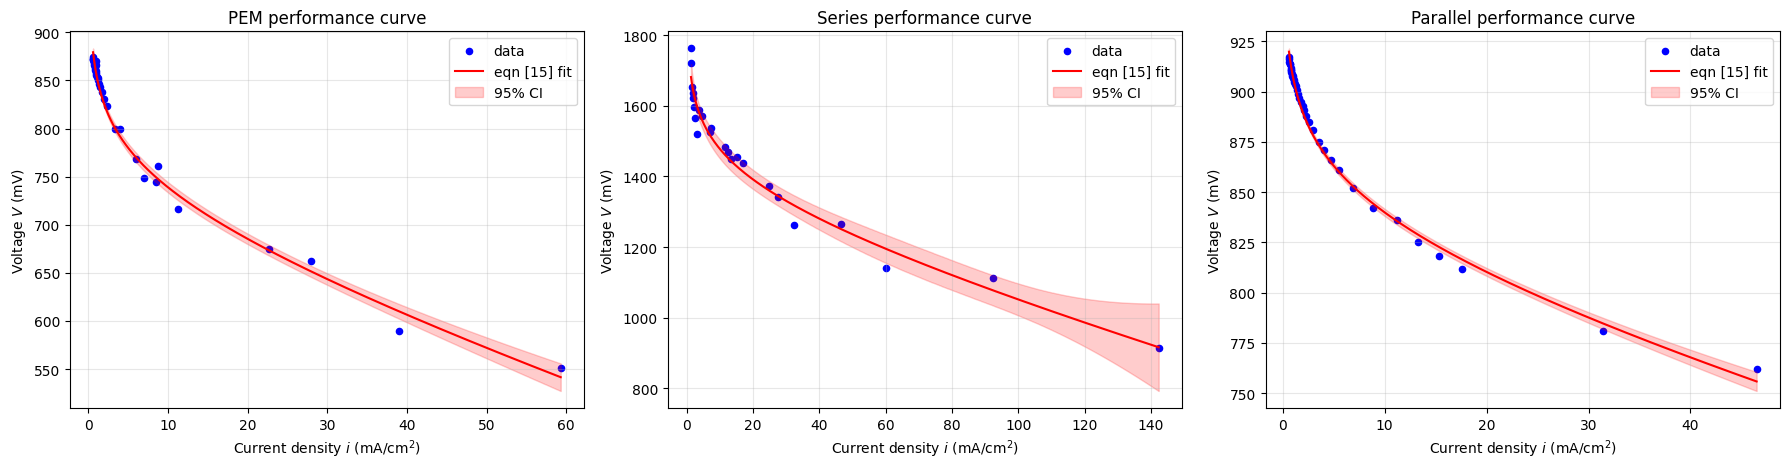

In [6]:
def conf_band(i_fit, p, cov, n_data, level=0.95):
    # Delta method: propagate the parameter covariance through the model.
    # This is the nonlinear analog of the module's confidence-band formula.
    eps = 1e-6
    J = np.array([(model(i_fit, *(p + eps*np.eye(len(p))[k])) - model(i_fit, *p)) / eps
                  for k in range(len(p))]).T
    se = np.sqrt(np.einsum("ij,jk,ik->i", J, cov, J))
    return t.ppf(0.5 + level/2, n_data - len(p)) * se   # t-score instead of 1.96 (small n)

fig, axes = plt.subplots(1, len(datasets), figsize=(6 * len(datasets), 4.8))
for ax, (name, i, V) in zip(axes, datasets):
    p, cov = fits[name]
    i_fit = np.linspace(i.min(), i.max(), 400)
    V_fit = model(i_fit, *p)
    band = conf_band(i_fit, p, cov, len(i))

    ax.scatter(i, V, color="b", s=20, label="data")
    ax.plot(i_fit, V_fit, "r-", label="eqn [15] fit")
    ax.fill_between(i_fit, V_fit - band, V_fit + band, color="r", alpha=0.2, label="95% CI")
    ax.set_xlabel(r"Current density $i$ (mA/cm$^2$)")
    ax.set_ylabel(r"Voltage $V$ (mV)")
    ax.set_title(f"{name} performance curve")
    ax.legend()
    ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

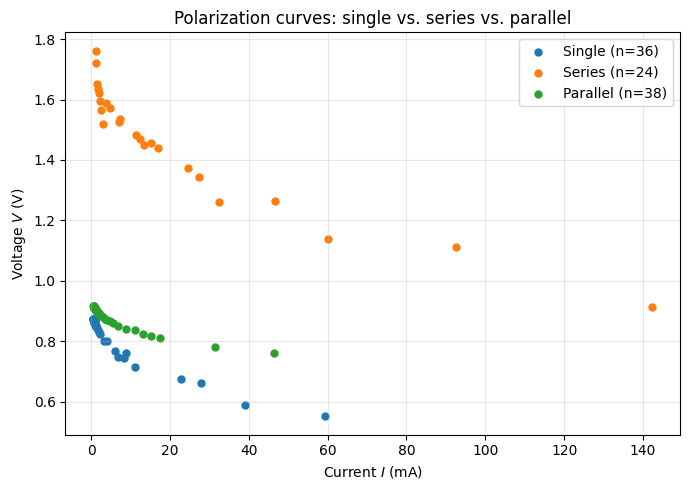

In [7]:
# Scatter: V vs I for single, series, and parallel (Google Sheet "Hydrogen Experiments")
h2_book = gc.open("Hydrogen Experiments")   # the Sheet's title as shown in Drive

def load_tab(tab):
    rows = h2_book.worksheet(tab).get_all_values()[1:]   # skip header row
    V, I = [], []
    for r in rows:
        # Column B = V (V), column C = I (mA); column A (R) ignored
        if len(r) > 2 and r[1] != "" and r[2] != "":
            V.append(float(r[1]))
            I.append(float(r[2]))
    return np.array(I), np.array(V)

configs = [("Single", "PEM Fuel Cell", "tab:blue"),
           ("Series", "Series", "tab:orange"),
           ("Parallel", "Parallel", "tab:green")]

fig, ax = plt.subplots(figsize=(7, 5))
for label, tab, color in configs:
    I, V = load_tab(tab)
    ax.scatter(I, V, s=25, color=color, label=f"{label} (n={len(I)})")

ax.set_xlabel(r"Current $I$ (mA)")
ax.set_ylabel(r"Voltage $V$ (V)")
ax.set_title("Polarization curves: single vs. series vs. parallel")
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

PEM: p_max = 3.211e-02 W/cm^2 at i = 59.30 mA/cm^2, V = 542 mV
Series: p_max = 1.304e-01 W/cm^2 at i = 142.30 mA/cm^2, V = 917 mV
Parallel: p_max = 3.515e-02 W/cm^2 at i = 46.50 mA/cm^2, V = 756 mV


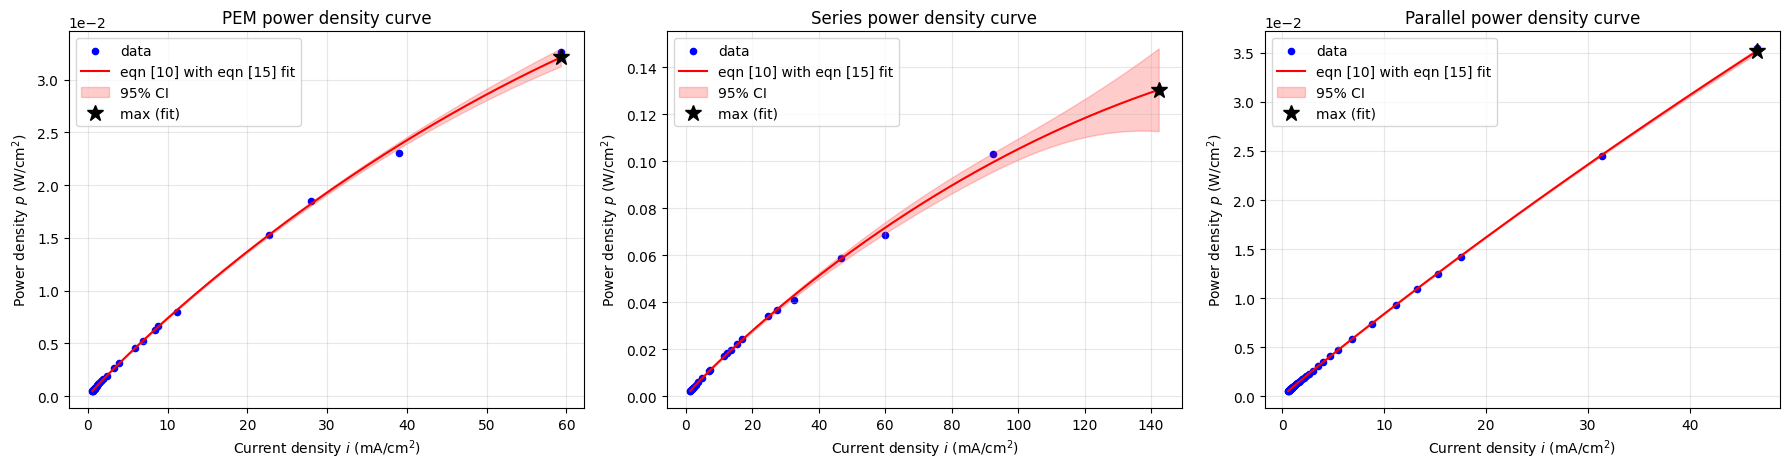

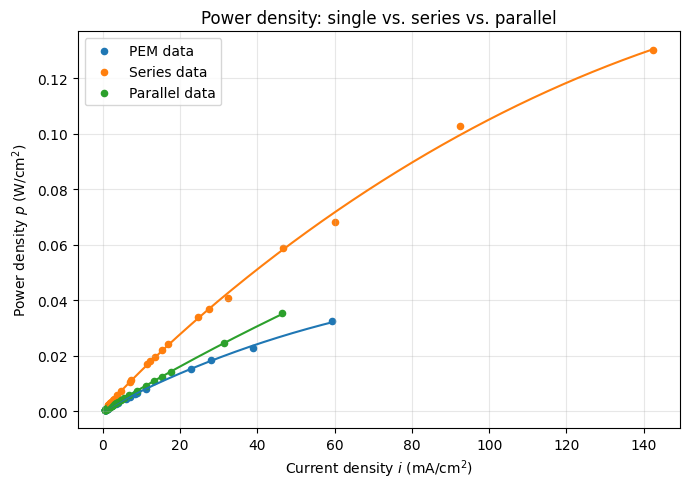

In [8]:
# Power density, eqn [10]: p = V * i
# V [mV] * i [mA/cm^2] = uW/cm^2  ->  x 1e-6  ->  W/cm^2 (handout units)
TO_W = 1e-6

fig, axes = plt.subplots(1, len(datasets), figsize=(6 * len(datasets), 4.8))
for ax, (name, i, V) in zip(axes, datasets):
    p_par, cov = fits[name]
    i_fit = np.linspace(i.min(), i.max(), 400)
    V_fit = model(i_fit, *p_par)                  # eqn [15]
    band = conf_band(i_fit, p_par, cov, len(i))

    p_data = V * i * TO_W                         # eqn [10], measured
    p_fit = V_fit * i_fit * TO_W                  # eqn [10] applied to eqn [15] fit
    p_band = band * i_fit * TO_W                  # i is exact, so the band scales by i

    k = np.argmax(p_fit)
    print(f"{name}: p_max = {p_fit[k]:.3e} W/cm^2 at i = {i_fit[k]:.2f} mA/cm^2, "
          f"V = {V_fit[k]:.0f} mV")

    ax.scatter(i, p_data, color="b", s=20, label="data")
    ax.plot(i_fit, p_fit, "r-", label="eqn [10] with eqn [15] fit")
    ax.fill_between(i_fit, p_fit - p_band, p_fit + p_band, color="r", alpha=0.2, label="95% CI")
    ax.plot(i_fit[k], p_fit[k], "k*", ms=12, label="max (fit)")
    ax.set_xlabel(r"Current density $i$ (mA/cm$^2$)")
    ax.set_ylabel(r"Power density $p$ (W/cm$^2$)")
    ax.set_title(f"{name} power density curve")
    ax.ticklabel_format(axis="y", style="sci", scilimits=(-2, 2))
    ax.legend()
    ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# Overlay of all three configurations
fig, ax = plt.subplots(figsize=(7, 5))
for (name, i, V), color in zip(datasets, ["tab:blue", "tab:orange", "tab:green"]):
    p_par, _ = fits[name]
    i_fit = np.linspace(i.min(), i.max(), 400)
    ax.scatter(i, V * i * TO_W, s=20, color=color, label=f"{name} data")
    ax.plot(i_fit, model(i_fit, *p_par) * i_fit * TO_W, color=color)
ax.set_xlabel(r"Current density $i$ (mA/cm$^2$)")
ax.set_ylabel(r"Power density $p$ (W/cm$^2$)")
ax.set_title("Power density: single vs. series vs. parallel")
ax.ticklabel_format(axis="y", style="sci", scilimits=(-2, 2))
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## Ethanol fuel cell — live Google Sheet `Et-Fuel cell`

This section uses **the same Google Colab authorization, `AREA`, equation [15] model, and power-density units** as the hydrogen section above. Run the hydrogen cells first, then run these cells.

**Default Day 2 comparison:** `5v%`, `10v%`, `13v%`, `2inseries 10v%`, and `2inparallel 10v%` (each listed in the actual Google Sheet). These have **voltage in column A (V)**, **current in column B (mA)**, and header rows that vary by tab. The loader automatically skips nonnumeric header rows and sorts by current density.

**Earlier runs:** `5 v%`, `9.6 v%`, `16.7 v%`, and `5 v% day2` can be enabled below if needed. They were recorded under different conditions and are not included by default. In particular, `5 v% day2` has numerical voltage entries of 82–110 despite a header saying V; the optional configuration explicitly treats those entries as **mV**, which should be verified against the lab notes.

**Data-quality note:** The previously reported 1.95 V series reading was corrected to 1.095 V in the updated source; verify that correction in the live Sheet. Also, `5v%` contains a **0.646 V** reading (with 3.48 mA) that differ from the neighboring trend. The source measurements remain **unchanged** in all plots and fits. Check the source measurements before interpreting fitted parameters or peaks. We do not automatically delete any data.
**Meter-range clarification (parallel run):** `2inparallel 10v%` used the 2 V voltage range and 200 mA current range; the other ethanol runs reportedly used 200 mV and 20 mA ranges. These are **instrument range settings, not unit-conversion factors**. The spreadsheet labels give voltage in V and current in mA for *all* runs, so we convert V → mV by multiplying by 1000 and retain current in mA for all runs. No extra factor of 10 is applied to the parallel experiment. If any values were copied as raw meter display digits rather than the labeled physical units, verify against the original instrument notes before fitting. Some earlier reported voltages exceed 200 mV, so the older range settings deserve verification.

**Normalization:** The parallel two-cell system uses a combined 2 cm² membrane area for current density and power density; all other configurations retain the original 1 cm² reference area (including series, for per-cell-area stack comparison). For the parallel condition, a residual-bootstrap percentile 95% confidence band replaces the unstable local-covariance band. Bootstrap intervals are approximate and rely on Equation [15] and residual-resampling assumptions.


**New mixed-cell conditions:** `H&Et-series` (1 cm² per-cell current-density reference) and `H&Et-parallel` (2 cm² total active membrane area). Both worksheet columns report voltage in V and current in mA. The parallel mixed-cell fit uses the same residual-bootstrap 95% confidence band as the ethanol-only parallel condition. These are mixed hydrogen–ethanol configurations, not additional ethanol-concentration measurements.


In [10]:
# The Google Sheet is named "Et-Fuel cell" in Drive, NOT "Et-Fuel cell(4).xlsx".
# Reuse gc (the authenticated gspread client) from the hydrogen section.
ethanol_book = gc.open("Et-Fuel cell")

# (plot label, exact worksheet/tab name, voltage conversion factor to mV)
# Meter setting: parallel run = 2 V / 200 mA; other runs reportedly = 200 mV / 20 mA.
# These are *measurement ranges*, not data multipliers. Since the columns
# are labeled V and mA for all tabs, voltage_to_mV = 1000 for every run.
# Do NOT multiply the parallel voltage or current by 10 based on the range.
ETHANOL_CONFIGS = [
    ("5 vol%", "5v%", 1000.0),
    ("10 vol%", "10v%", 1000.0),
    ("13 vol%", "13v%", 1000.0),
    ("Series (10 vol%)", "2inseries: 10v%", 1000.0),
    ("Parallel (10 vol%)", "2inparallel: 10v%", 1000.0),
    ("H+Et series", "H&Et-series", 1000.0),
    ("H+Et parallel", "H&Et-parallel", 1000.0),
]

# Set to True to include EARLIER runs in the same graphs (different run protocol).
INCLUDE_EARLIER_RUNS = False
if INCLUDE_EARLIER_RUNS:
    ETHANOL_CONFIGS += [
        ("5 vol% (earlier)", "5 v%", 1000.0),
        ("9.6 vol% (earlier)", "9.6 v%", 1000.0),
        ("16.7 vol% (earlier)", "16.7 v%", 1000.0),
        # Confirm the voltage unit in the original lab notes before using this tab:
        # ("5 vol% (day2 alternate)", "5 v% day2", 1.0),
    ]

def load_ethanol_sheet(tab, voltage_to_mV=1000.0, active_area=1.0):
    rows = ethanol_book.worksheet(tab).get_all_values()
    measured = []
    for row_number, r in enumerate(rows, start=1):
        # EtOH workbook: A = voltage, B = current (unlike hydrogen B/C).
        if len(r) < 2:
            continue
        try:
            v = float(str(r[0]).strip())
            current = float(str(r[1]).strip())
        except (ValueError, TypeError):
            continue  # skip titles, column headings, empty rows
        if np.isfinite(v) and np.isfinite(current) and current > 0 and v >= 0:
            measured.append((current / active_area, v * voltage_to_mV))

    if len(measured) < 6:
        raise ValueError(f"'{tab}' has only {len(measured)} valid data rows; check its columns and units.")
    data = np.asarray(measured, dtype=float)
    order = np.argsort(data[:, 0], kind="stable")
    return data[order, 0], data[order, 1]  # i [mA/cm²], V [mV]

# Area convention: each membrane is 1 cm². Parallel configurations use
# total active area (2 cm²); series configurations use one-cell reference area.
# This applies to both ethanol-only and mixed hydrogen–ethanol pairings.
AREA_BY_CONDITION = {
    "Parallel (10 vol%)": 2.0,
    "H+Et parallel": 2.0,
}
def condition_area(name):
    return AREA_BY_CONDITION.get(name, 1.0)

ethanol_datasets = []
for name, tab, conversion in ETHANOL_CONFIGS:
    i, V = load_ethanol_sheet(tab, conversion, active_area=condition_area(name))
    ethanol_datasets.append((name, i, V))
    print(f"{name}: {len(i)} points | i: {i.min():.2f}–{i.max():.2f} mA/cm² | "
          f"V: {V.min():.1f}–{V.max():.1f} mV")
print("All recorded points have been retained (no outlier removal).")
print("Meter ranges: parallel = 2 V / 200 mA; others reported = 200 mV / 20 mA.")
print("All columns interpreted as voltage in V and current in mA; ranges do not create a ×10 correction.")

print("Normalization: 2 cm² for both parallel conditions; 1 cm² reference area for single-cell and series conditions.")


5 vol%: 39 points | i: 0.46–8.20 mA/cm² | V: 104.0–718.0 mV
10 vol%: 40 points | i: 0.47–8.95 mA/cm² | V: 113.0–732.0 mV
13 vol%: 42 points | i: 0.45–9.56 mA/cm² | V: 117.0–762.0 mV
Series (10 vol%): 46 points | i: 0.88–11.48 mA/cm² | V: 152.0–1327.0 mV
Parallel (10 vol%): 38 points | i: 0.05–13.35 mA/cm² | V: 54.0–763.0 mV
H+Et series: 27 points | i: 0.95–47.90 mA/cm² | V: 9.0–2000.0 mV
H+Et parallel: 25 points | i: 0.28–16.00 mA/cm² | V: 391.0–869.0 mV
All recorded points have been retained (no outlier removal).
Meter ranges: parallel = 2 V / 200 mA; others reported = 200 mV / 20 mA.
All columns interpreted as voltage in V and current in mA; ranges do not create a ×10 correction.
Normalization: 2 cm² for both parallel conditions; 1 cm² reference area for single-cell and series conditions.


### Ethanol parameter fitting — equation [15]

The same five-parameter function `model(i, C, B, R, w, z)` is used. For ethanol, the existing hydrogen `full_fit` function can fail when its initial guesses fall outside its bounds, so this section uses **multiple valid starting guesses** and keeps the least-squares fit with the smallest residual error. The raw data are never adjusted.

Approximate 95% confidence bands are attempted whenever the covariance matrix is finite, regardless of R²; interpret the bands cautiously when fit parameters are poorly identifiable. **Fitted peak power is a model-based estimate within the measured current range**, not an extrapolation or an independently measured maximum.

In [11]:
# Equation [15] is already defined as model(i, C, B, R, w, z) above.

def ethanol_full_fit(i, V):
    linear_guess, _ = linear_scale_fit(i, V)
    lower = np.array([0, 0, 0, 0, 0], dtype=float)
    upper = np.array([5000, 1000, 200, 1000, 1.0], dtype=float)
    first_guess = np.array([
        max(linear_guess[0], V.max()), max(linear_guess[1], 0.01),
        max(linear_guess[2], 0.01), 1.0, 0.03
    ], dtype=float)
    # Ensure each initial guess strictly satisfies the bounds.
    first_guess = np.clip(first_guess, lower + 1e-7, upper - 1e-7)
    guesses = [
        first_guess,
        [V.max(), 20, 5, 0.5, 0.1],
        [min(V.max() * 1.15, 4999), 30, 1, 5, 0.05],
        [V.max(), 75, 10, 2, 0.15],
    ]

    best = None
    for initial in guesses:
        try:
            p, cov = curve_fit(model, i, V, p0=initial,
                               bounds=(lower, upper), maxfev=60000)
            sse = float(np.sum((V - model(i, *p)) ** 2))
            if best is None or sse < best[0]:
                best = (sse, p, cov)
        except (RuntimeError, ValueError, FloatingPointError):
            continue
    if best is None:
        raise RuntimeError("No five-parameter ethanol fit converged.")
    sse, p, cov = best
    denominator = np.sum((V - V.mean()) ** 2)
    r2 = 1 - sse / denominator if denominator > 0 else np.nan
    return p, cov, r2

ethanol_fits = {}
for name, i, V in ethanol_datasets:
    p, cov, r2 = ethanol_full_fit(i, V)
    # A poor fit, ill-defined parameter errors, or boundary estimates
    # makes the usual local-linearized confidence band hard to interpret.
    sds = np.sqrt(np.maximum(np.diag(cov), 0))
    stable = bool(np.isfinite(cov).all() and np.isfinite(sds).all())
    ethanol_fits[name] = (p, cov, r2, stable)
    print(f"--- {name} (R² = {r2:.4f}; 95% CI {'shown' if stable else 'not shown'})")
    for param, value, sd in zip(["C", "B", "R", "w", "z"], p, sds):
        print(f"  {param} = {value:.4g} ± {sd:.2g}")
    if not stable:
        print("  NOTE: weak or unstable fit; interpret estimated parameters cautiously.")

--- 5 vol% (R² = 0.9386; 95% CI shown)
  C = 729.6 ± 8.1e+02
  B = 178.7 ± 1.4e+02
  R = 1.051e-12 ± 2.2e+02
  w = 70.72 ± 8.8e+02
  z = 0.2318 ± 0.88
--- 10 vol% (R² = 0.9980; 95% CI shown)
  C = 690.6 ± 4.4
  B = 173.7 ± 12
  R = 21.86 ± 3.6
  w = 0.02775 ± 0.053
  z = 1 ± 0.21
--- 13 vol% (R² = 0.9863; 95% CI shown)
  C = 650.3 ± 14
  B = 208.7 ± 35
  R = 30.92 ± 12
  w = 0.002331 ± 0.31
  z = 1 ± 14
--- Series (10 vol%) (R² = 0.9985; 95% CI shown)
  C = 1367 ± 3.3
  B = 156.3 ± 20
  R = 50.53 ± 3.4
  w = 0.004674 ± 0.0048
  z = 1 ± 0.088
--- Parallel (10 vol%) (R² = 0.9978; 95% CI shown)
  C = 765.4 ± 3.7
  B = 2.923 ± 4.8
  R = 42.03 ± 2.9
  w = 0.0002342 ± 0.056
  z = 1 ± 18
--- H+Et series (R² = 0.9257; 95% CI shown)
  C = 1529 ± 5.2e+06
  B = 712.7 ± 1.1e+02
  R = 7.527 ± 6.4e+04
  w = 0.01368 ± 5.2e+06
  z = 1.358e-06 ± 4.7e+06
--- H+Et parallel (R² = 0.9885; 95% CI shown)
  C = 858.4 ± 2.9e+07
  B = 105.2 ± 17
  R = 21.38 ± 1.5e+07
  w = 25.59 ± 2.9e+07
  z = 3.13e-09 ± 5.9e+

In [12]:
# 95% confidence bands for ethanol performance curves.
# Parallel cells use a residual-bootstrap percentile interval to avoid the
# numerically explosive local covariance estimate of the five-parameter fit.
# This interval describes uncertainty in the fitted mean curve conditional
# on the fitted model and the residual-resampling assumptions.
from scipy.optimize import curve_fit

PARALLEL_LABELS = {"Parallel (10 vol%)", "H+Et parallel"}
BOOTSTRAP_REPS = 250
BOOTSTRAP_SEED = 4100


def ethanol_plot_interval(name, i_fit, i, V, params, cov, n_boot=BOOTSTRAP_REPS):
    if name not in PARALLEL_LABELS:
        if not np.isfinite(cov).all():
            return None
        try:
            halfwidth = conf_band(i_fit, params, cov, len(i))
            if np.isfinite(halfwidth).all():
                center = model(i_fit, *params)
                return center - halfwidth, center + halfwidth
        except (ValueError, FloatingPointError, OverflowError):
            pass
        return None

    # Bootstrap: re-fit the identical Equation [15] model at each resample.
    rng = np.random.default_rng(BOOTSTRAP_SEED)
    residuals = V - model(i, *params)
    residuals = residuals - np.mean(residuals)
    expected = model(i, *params)
    lower_bounds = [0, 0, 0, 0, 0]
    upper_bounds = [5000, 1000, 200, 1000, 1.0]
    predictions = []
    for _ in range(n_boot):
        V_resampled = expected + rng.choice(residuals, size=len(residuals), replace=True)
        try:
            p_boot, _ = curve_fit(
                model, i, V_resampled, p0=params,
                bounds=(lower_bounds, upper_bounds), maxfev=10000
            )
            pred = model(i_fit, *p_boot)
            if np.isfinite(pred).all():
                predictions.append(pred)
        except (RuntimeError, ValueError, FloatingPointError, OverflowError):
            continue

    print(f"{name}: {len(predictions)}/{n_boot} bootstrap refits converged")
    if len(predictions) < max(50, int(n_boot * 0.7)):
        print("Bootstrap fit success too low for a reliable displayed 95% interval.")
        return None
    samples = np.asarray(predictions)
    return np.percentile(samples, 2.5, axis=0), np.percentile(samples, 97.5, axis=0)

# Calculate each band once and use the same interval for voltage and power.
ethanol_intervals = {}
for name, i, V in ethanol_datasets:
    p, cov, r2, stable = ethanol_fits[name]
    i_fit = np.linspace(i.min(), i.max(), 400)
    ethanol_intervals[name] = ethanol_plot_interval(name, i_fit, i, V, p, cov)


Parallel (10 vol%): 250/250 bootstrap refits converged
H+Et parallel: 250/250 bootstrap refits converged


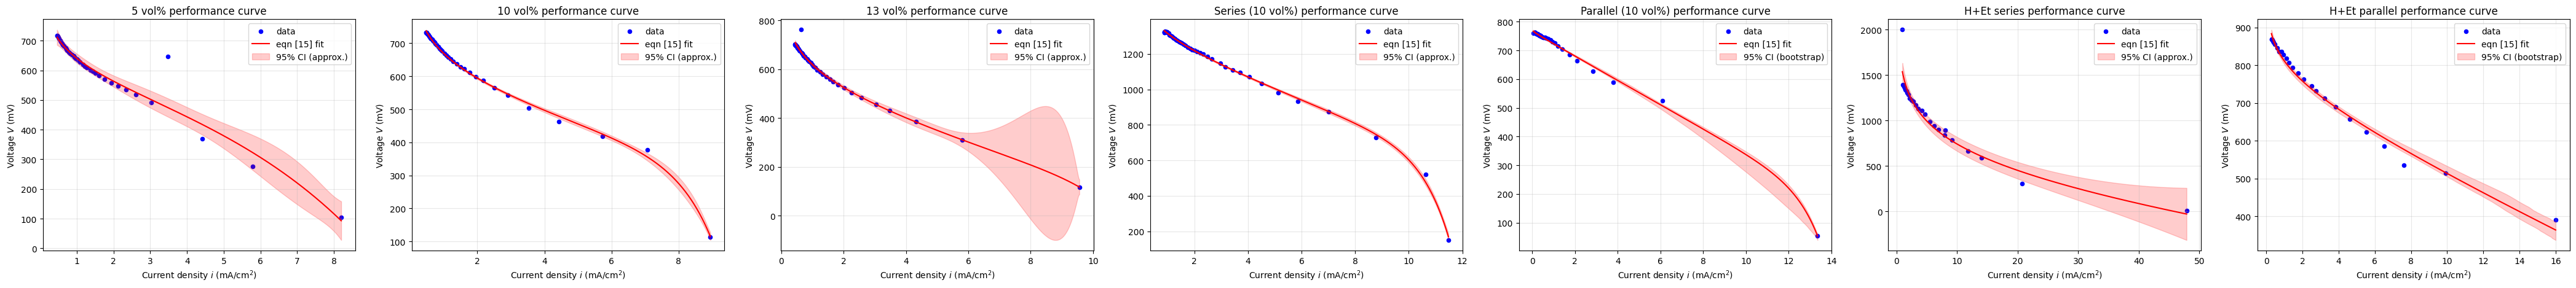

In [13]:
# Ethanol performance curves: V (mV) vs current density i (mA/cm²)
fig, axes = plt.subplots(1, len(ethanol_datasets),
                         figsize=(6 * len(ethanol_datasets), 4.8), squeeze=False)
for ax, (name, i, V) in zip(axes.ravel(), ethanol_datasets):
    p, cov, r2, stable = ethanol_fits[name]
    i_fit = np.linspace(i.min(), i.max(), 400)
    V_fit = model(i_fit, *p)

    ax.scatter(i, V, s=20, color="b", label="data")
    ax.plot(i_fit, V_fit, "r-", label="eqn [15] fit")
    interval = ethanol_intervals[name]
    if interval is not None:
        lo, hi = interval
        label = "95% CI (bootstrap)" if name in PARALLEL_LABELS else "95% CI (approx.)"
        ax.fill_between(i_fit, lo, hi, color="r", alpha=0.2, label=label)
    else:
        print(f"{name}: 95% CI unavailable from this fit; no interval fabricated.")
    ax.set_xlabel(r"Current density $i$ (mA/cm$^2$)")
    ax.set_ylabel(r"Voltage $V$ (mV)")
    ax.set_title(f"{name} performance curve")
    ax.legend()
    ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()


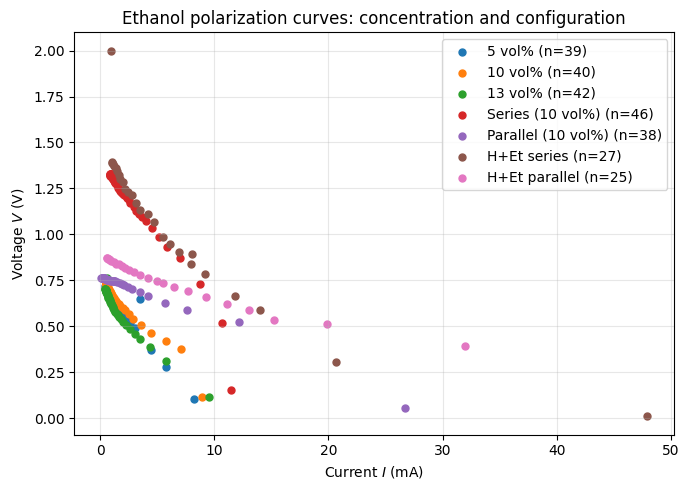

In [14]:
# Ethanol raw polarization comparison (same type of graph as hydrogen).
# Converts the model's units back from mV to V; since AREA is in cm²,
# measured current I [mA] = i [mA/cm²] * effective area [cm²].
fig, ax = plt.subplots(figsize=(7, 5))
for name, i, V in ethanol_datasets:
    ax.scatter(i * condition_area(name), V / 1000.0, s=25, label=f"{name} (n={len(i)})")
ax.set_xlabel(r"Current $I$ (mA)")
ax.set_ylabel(r"Voltage $V$ (V)")
ax.set_title("Ethanol polarization curves: concentration and configuration")
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

5 vol%: measured max = 2.248e-03 W/cm² at i = 3.48 mA/cm²; fitted max = 1.901e-03 W/cm² at i = 5.21 mA/cm²
10 vol%: measured max = 2.665e-03 W/cm² at i = 7.07 mA/cm²; fitted max = 2.534e-03 W/cm² at i = 6.72 mA/cm²
13 vol%: measured max = 1.804e-03 W/cm² at i = 5.80 mA/cm²; fitted max = 1.811e-03 W/cm² at i = 6.23 mA/cm²
Series (10 vol%): measured max = 6.401e-03 W/cm² at i = 8.78 mA/cm²; fitted max = 6.550e-03 W/cm² at i = 8.69 mA/cm²
Parallel (10 vol%): measured max = 3.196e-03 W/cm² at i = 6.10 mA/cm²; fitted max = 3.443e-03 W/cm² at i = 8.85 mA/cm²
H+Et series: measured max = 8.218e-03 W/cm² at i = 14.00 mA/cm²; fitted max = 9.034e-03 W/cm² at i = 19.78 mA/cm²
H+Et parallel: measured max = 6.256e-03 W/cm² at i = 16.00 mA/cm²; fitted max = 5.831e-03 W/cm² at i = 15.49 mA/cm²


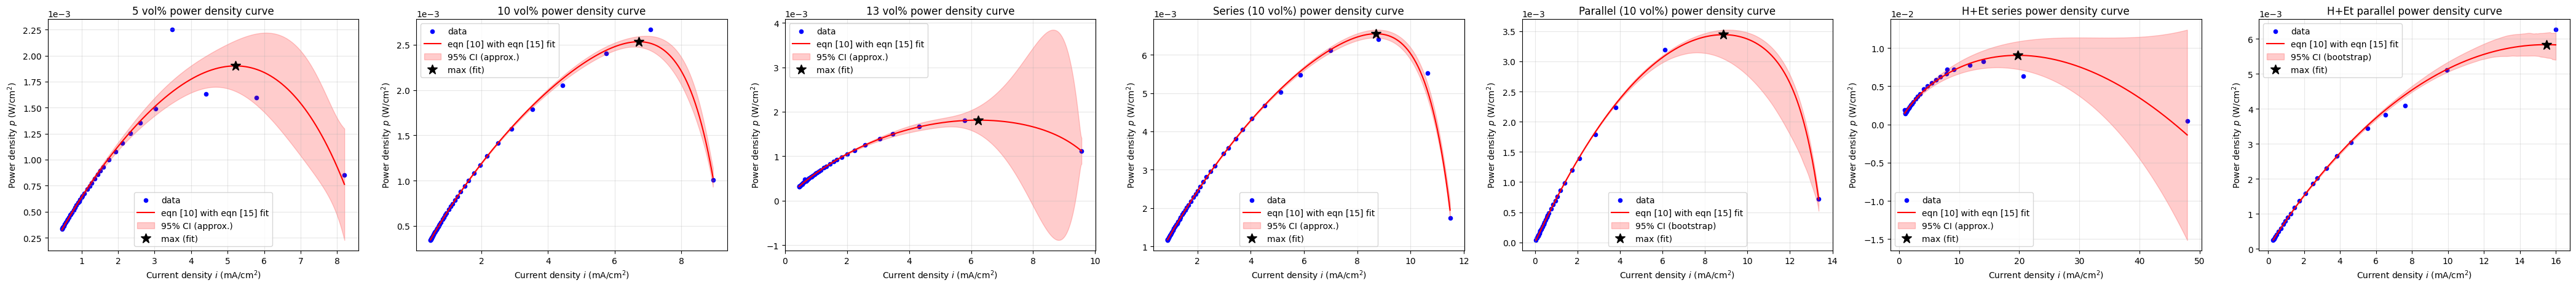

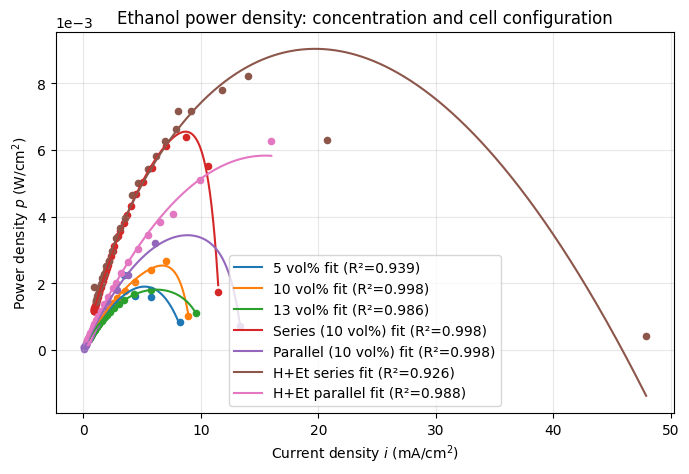

In [15]:
# Ethanol power-density curves — eqn [10]: p = V * i
# mV * mA/cm² = µW/cm², so multiply by 1e-6 to obtain W/cm².
fig, axes = plt.subplots(1, len(ethanol_datasets),
                         figsize=(6 * len(ethanol_datasets), 4.8), squeeze=False)
for ax, (name, i, V) in zip(axes.ravel(), ethanol_datasets):
    p_par, cov, r2, stable = ethanol_fits[name]
    i_fit = np.linspace(i.min(), i.max(), 400)
    V_fit = model(i_fit, *p_par)
    p_data = V * i * 1e-6
    p_fit = V_fit * i_fit * 1e-6
    k_fit = int(np.argmax(p_fit))
    k_observed = int(np.argmax(p_data))
    print(f"{name}: measured max = {p_data[k_observed]:.3e} W/cm² "
          f"at i = {i[k_observed]:.2f} mA/cm²; "
          f"fitted max = {p_fit[k_fit]:.3e} W/cm² "
          f"at i = {i_fit[k_fit]:.2f} mA/cm²")

    ax.scatter(i, p_data, color="b", s=20, label="data")
    ax.plot(i_fit, p_fit, "r-", label="eqn [10] with eqn [15] fit")
    interval = ethanol_intervals[name]
    if interval is not None:
        lo, hi = interval
        label = "95% CI (bootstrap)" if name in PARALLEL_LABELS else "95% CI (approx.)"
        ax.fill_between(i_fit, lo * i_fit * 1e-6, hi * i_fit * 1e-6,
                        color="r", alpha=0.2, label=label)
    ax.plot(i_fit[k_fit], p_fit[k_fit], "k*", ms=12, label="max (fit)")
    ax.set_xlabel(r"Current density $i$ (mA/cm$^2$)")
    ax.set_ylabel(r"Power density $p$ (W/cm$^2$)")
    ax.set_title(f"{name} power density curve")
    ax.ticklabel_format(axis="y", style="sci", scilimits=(-2, 2))
    ax.legend()
    ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# Overlay: all ethanol conditions in a single power-density comparison.
fig, ax = plt.subplots(figsize=(7, 5))
for name, i, V in ethanol_datasets:
    p_par, _, r2, _ = ethanol_fits[name]
    i_fit = np.linspace(i.min(), i.max(), 400)
    line, = ax.plot(i_fit, model(i_fit, *p_par) * i_fit * 1e-6,
                    label=f"{name} fit (R²={r2:.3f})")
    ax.scatter(i, V * i * 1e-6, s=20, color=line.get_color())
ax.set_xlabel(r"Current density $i$ (mA/cm$^2$)")
ax.set_ylabel(r"Power density $p$ (W/cm$^2$)")
ax.set_title("Ethanol power density: concentration and cell configuration")
ax.ticklabel_format(axis="y", style="sci", scilimits=(-2, 2))
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()